# 01 - scene generation

there is no real data here, everything is trained on synthetic "scenes" that I generate myself. so first: what is a scene?

a scene is a 2D site in a `[-1, 1]` box with

- a bunch of **sources** (things that *could* leak), the first few of them are actually **leaking**
- 6 to 10 **sensors**, each reports one concentration value per timestep
- **wind** (speed + direction) over 100 timesteps

the models (notebooks 02 and 03) then have to find the leak(s) from the sensor readings and the wind only.

code is in `leaknet/simulation.py`, datasets are written with `scripts/generate_scenes.py`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from leaknet import plotting, simulation

# a handful of scenes to look at (same function that the generation script uses)
scenes = simulation.generate_collection(n_samples=6, n_leak_min=1, n_leak_max=2, seed=3, progress=False)
sample = scenes[0]

{key: np.shape(value) for key, value in sample.items()}

{'n_timesteps': (),
 'time': (100,),
 'n_sensors': (),
 'pos_sensors': (10, 2),
 'con_sensors': (100, 10),
 'msk_sensors': (10,),
 'n_sources': (),
 'pos_sources': (30, 2),
 'n_leaks': (),
 'Q_leaks': (100, 2),
 'pos_leaks': (2, 2),
 'msk_leaks': (2,),
 'wind_speed': (100,),
 'wind_direc': (100,),
 'wind_covar': (2, 2)}

## the plume

concentration around a leak comes from `atmospheric_dispersion(x, y, Q, u)`, in the local wind frame of the leak (x = downwind, y = crosswind). watch out, this is **not** a physical dispersion model! I just built the formula by hand until the plumes looked plausible: no wind -> gas sits in a round blob around the leak, more wind -> blob shrinks and a `1/x` plume stretches out downwind.

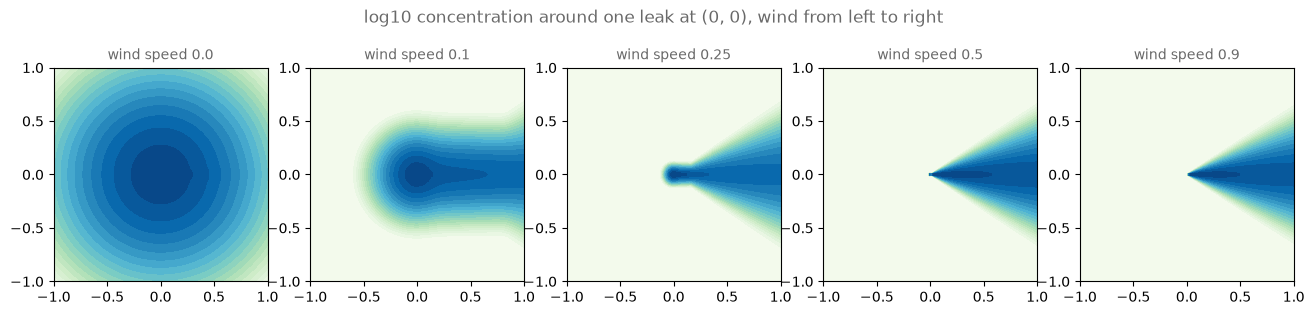

In [2]:
x = np.linspace(-1, 1, 200)
X, Y = np.meshgrid(x, x)

fig, axes = plt.subplots(1, 5, figsize=(16, 3.4))
for ax, u in zip(axes, [0.0, 0.1, 0.25, 0.5, 0.9]):
    # wind blows in +x direction here, so the global frame is already the local wind frame (crosswind = |y|)
    Z = simulation.atmospheric_dispersion(X, np.abs(Y), Q=1.0, u=u)
    ax.contourf(x, x, np.log10(Z + 1e-5), levels=20, cmap="GnBu")
    ax.set_title(f"wind speed {u}", fontsize=10, color="dimgray")
    ax.set_aspect("equal")
fig.suptitle("log10 concentration around one leak at (0, 0), wind from left to right", color="dimgray");

## the wind

speed and direction are random walks that get pulled towards a bias value. every 20 steps a new bias is drawn (weibull for speed, uniform for direction), so the wind keeps a regime for a while and then changes.

third panel = the "wind covariance": a blob that starts round and gets squished across the wind direction at every timestep (more in strong wind). idea: a measure for how well a leak can be located along which axis. it's stored with every scene and used later as the shape of the target blobs in the heatmap losses (notebook 03).

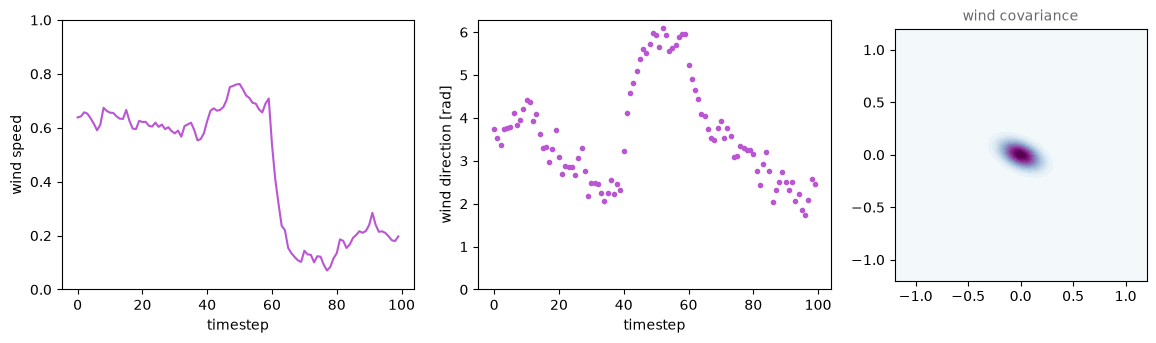

In [3]:
plotting.plot_wind(sample);

## one scene over time

green triangles = leaks, red pentagons = sensors, black dots = all the other sources. arrow = wind.

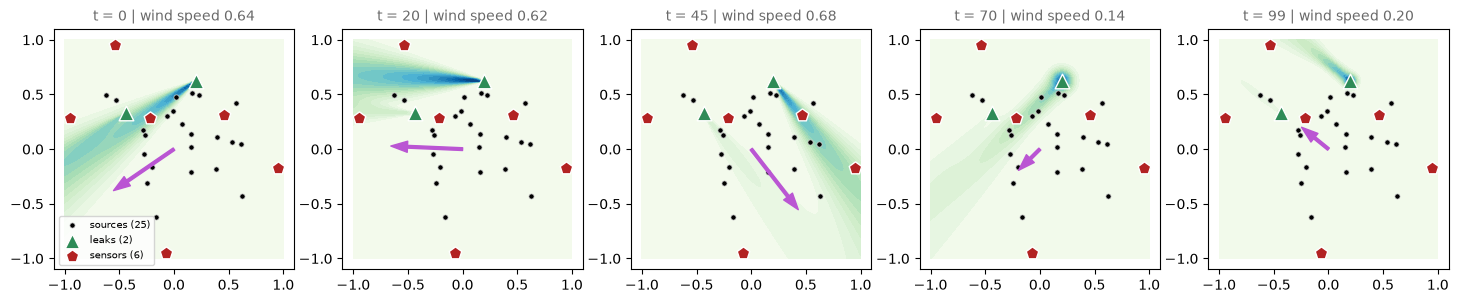

In [4]:
field = simulation.concentration_field(sample)

fig, axes = plt.subplots(1, 5, figsize=(18, 3.8))
for ax, t in zip(axes, [0, 20, 45, 70, 99]):
    plotting.plot_scene(sample, t, ax=ax, field=field)
axes[0].legend(loc="lower left", fontsize=7)
fig.savefig("../docs/figures/scene.png", dpi=110, bbox_inches="tight")

the model only gets to see the row of numbers per sensor below. raw concentrations span many orders of magnitude, so they are log-normalized to roughly `[0, 1]` with `(log10(c) + 5.2) / 6`. everything below `1e-5` is exactly 0, and padded sensors (scenes with fewer than 10 sensors) are filled with -1.

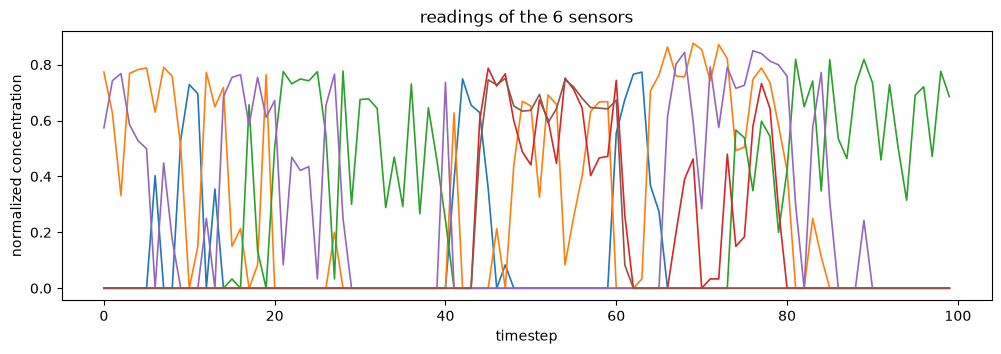

In [5]:
n_sensors = int(sample["n_sensors"])

fig, ax = plt.subplots(figsize=(12, 3.5))
ax.plot(sample["time"], sample["con_sensors"][:, :n_sensors], lw=1.2)
ax.set(xlabel="timestep", ylabel="normalized concentration", title=f"readings of the {n_sensors} sensors");

there is also a plotly version with a slider over the timesteps for looking at a scene interactively. (not executed here, makes the notebook huge)

In [6]:
# plotting.animate_scene(sample).show()

## a few more scenes

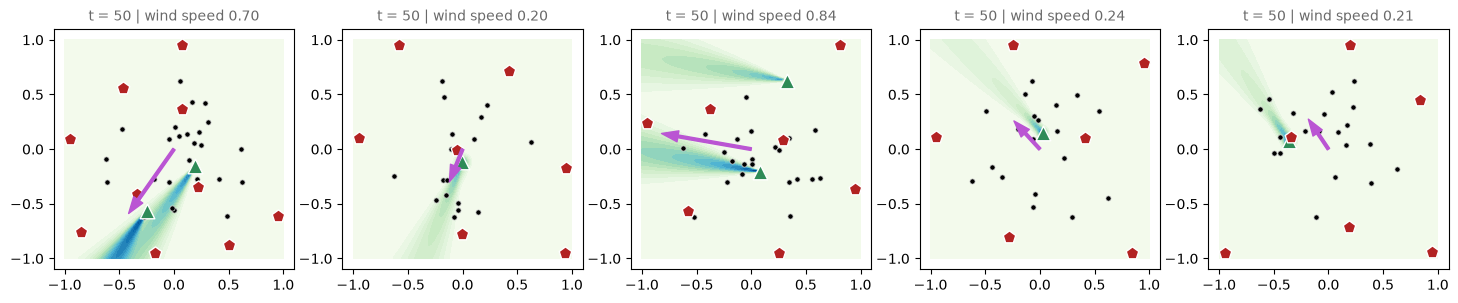

In [7]:
fig, axes = plt.subplots(1, 5, figsize=(18, 3.8))
for ax, scene in zip(axes, scenes[1:]):
    plotting.plot_scene(scene, t=50, ax=ax)

## sensor layouts

sensors are placed with poisson disk sampling so they are spread out nicely. a dataset does **not** get a new layout for every scene! a fixed set of 50 layouts is generated up front and every scene just picks one of them. keeps the generation simple, but it means train and validation scenes share their layouts -> notebook 02 checks what that does to the results.

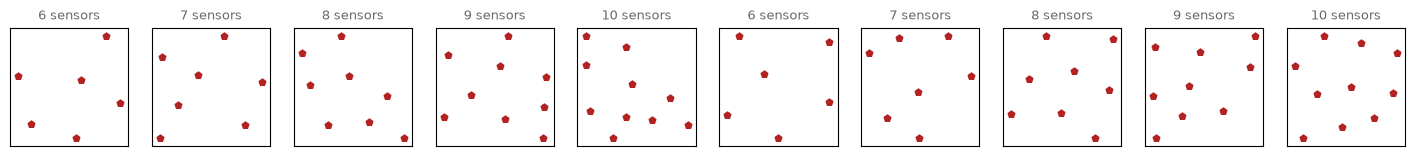

In [8]:
simulation.set_seed(0)
patterns = simulation.generate_sensor_patterns(n_sensor_patterns=10, n_sensor_min=6, n_sensor_max=10)

fig, axes = plt.subplots(1, 10, figsize=(18, 2))
for ax, pattern in zip(axes, patterns):
    ax.scatter(*pattern.T, s=25, marker="p", color="firebrick")
    ax.set(xlim=(-1.1, 1.1), ylim=(-1.1, 1.1), xticks=[], yticks=[], aspect="equal")
    ax.set_title(f"{len(pattern)} sensors", fontsize=9, color="dimgray")

## dataset statistics

quick look at the first 2000 scenes of the single leak dataset used in notebook 02 (`data/single_leak_20k.h5`, see README for how to generate it).

share of readings that are exactly 0 (below detection): 0.63
share of readings that are padding (-1):               0.20
mean distance of a leak to the center:                  0.431


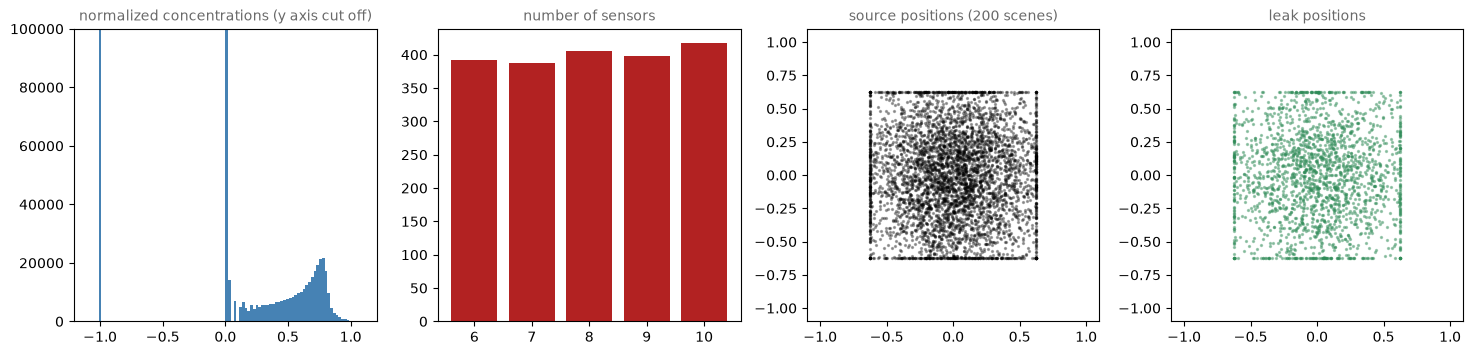

In [9]:
from pathlib import Path

from leaknet.data import load_scenes

path = Path("../data/single_leak_20k.h5")
data = load_scenes(path, 2000) if path.exists() else simulation.generate_collection(2000, seed=0, progress=False)

con = np.array([el["con_sensors"] for el in data]).reshape(-1)
leaks = np.array([el["pos_leaks"][0] for el in data])
sources = np.concatenate([el["pos_sources"][: el["n_sources"]] for el in data[:200]])

fig, axes = plt.subplots(1, 4, figsize=(18, 3.8))
axes[0].hist(con, bins=100, range=[-1.1, 1.1], color="steelblue")
axes[0].set_ylim(0, len(con) * 0.05)
axes[0].set_title("normalized concentrations (y axis cut off)", fontsize=10, color="dimgray")
axes[1].hist([int(el["n_sensors"]) for el in data], bins=np.arange(5.5, 11.5), color="firebrick", rwidth=0.8)
axes[1].set_title("number of sensors", fontsize=10, color="dimgray")
axes[2].scatter(*sources.T, s=2, color="black", alpha=0.3)
axes[2].set_title("source positions (200 scenes)", fontsize=10, color="dimgray")
axes[3].scatter(*leaks.T, s=2, color="seagreen", alpha=0.4)
axes[3].set_title("leak positions", fontsize=10, color="dimgray")
for ax in axes[2:]:
    ax.set(xlim=(-1.1, 1.1), ylim=(-1.1, 1.1), aspect="equal")

print(f"share of readings that are exactly 0 (below detection): {np.mean(con == 0):.2f}")
print(f"share of readings that are padding (-1):               {np.mean(con == -1):.2f}")
print(f"mean distance of a leak to the center:                  {np.linalg.norm(leaks, axis=1).mean():.3f}")

things to note:

- the spikes at 0 and -1 are the "no signal" readings and the padded sensors. well over half of all readings are exactly 0: as soon as there is some wind, a sensor only sees something while it sits inside the narrow downwind cone of a leak.
- sources are normalized so that their bounding box is always exactly `[-0.625, 0.625]`. so leaks never sit near the border of the site, while sensors go out to `±0.95`. side effect that I only noticed in this plot: the outermost sources land exactly on the border of that box, and so do the leaks whenever one of those gets picked (the lines in the two scatter plots).
- a model that always answers "leak is in the center" is at a mean distance of about 0.43. this is the number to beat in notebook 02.